## Loading Dataset

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/raw")
csv_files = list(data_path.glob("*.csv"))

print("CSV Files Found:")
for file in csv_files:
    print(file.name)

df = pd.read_csv(csv_files[0])

print("\nDataset Shape:", df.shape)
df.head()

CSV Files Found:
all_tickets_processed_improved_v3.csv

Dataset Shape: (47837, 2)


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


## Understanding the Dataset

In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (47837, 2)

Column Names:
['Document', 'Topic_group']

Missing Values:
Document       0
Topic_group    0
dtype: int64

Duplicate Rows: 0


## Analyzing Ticket Categories

In [3]:
print("Category Distribution:")
print(df["Topic_group"].value_counts())

print("\nNumber of Categories:", df["Topic_group"].nunique())

Category Distribution:
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

Number of Categories: 8


## Analyzing Category Distribution

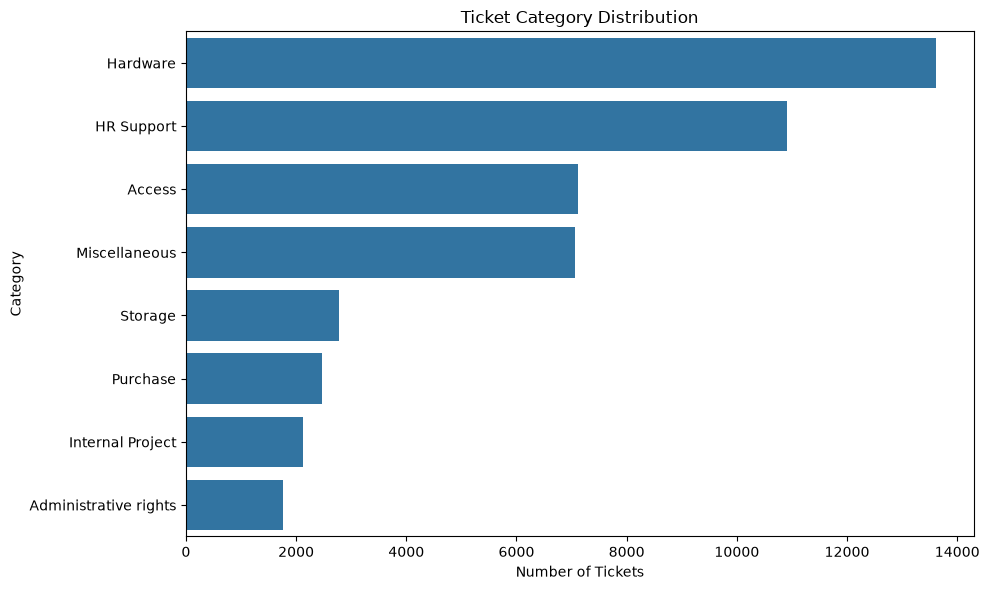

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="Topic_group",
    order=df["Topic_group"].value_counts().index
)

plt.title("Ticket Category Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Category")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Preparing Ticket Text

In [5]:
df["Document"] = df["Document"].fillna("").astype(str)
df["Document"] = df["Document"].str.strip()

df[["Document", "Topic_group"]].head()

,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


## Cleaning Ticket Text

In [6]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["cleaned_text"] = df["Document"].apply(clean_text)

df[["Document", "cleaned_text"]].head()

,Document,cleaned_text
0,connection with icon icon dear please setup ic...,connection with icon icon dear please setup ic...
1,work experience user work experience user hi w...,work experience user work experience user hi w...
2,requesting for meeting requesting meeting hi p...,requesting for meeting requesting meeting hi p...
3,reset passwords for external accounts re expir...,reset passwords for external accounts re expir...
4,mail verification warning hi has got attached ...,mail verification warning hi has got attached ...


## Splitting the Dataset

In [7]:
from sklearn.model_selection import train_test_split

X = df["cleaned_text"]
y = df["Topic_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 38269
Testing Samples: 9568


## Creating TF-IDF Features

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (38269, 144869)
Testing TF-IDF Shape: (9568, 144869)


## Training Classification Models

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

predictions = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions[name] = model.predict(X_test_tfidf)

print("All classification models trained successfully.")

All classification models trained successfully.


## Evaluating Classification Models

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

evaluation = []

for name, prediction in predictions.items():
    evaluation.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, prediction, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, prediction, average="weighted", zero_division=0)
    })

evaluation_df = pd.DataFrame(evaluation)

evaluation_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.854306,0.861407,0.854306,0.854042
1,Naive Bayes,0.698370,0.785047,0.698370,0.682430
2,Linear SVM,0.862981,0.863945,0.862981,0.862968


## Comparing Model Performance## Comparing Model Performance

<Figure size 900x500 with 0 Axes>

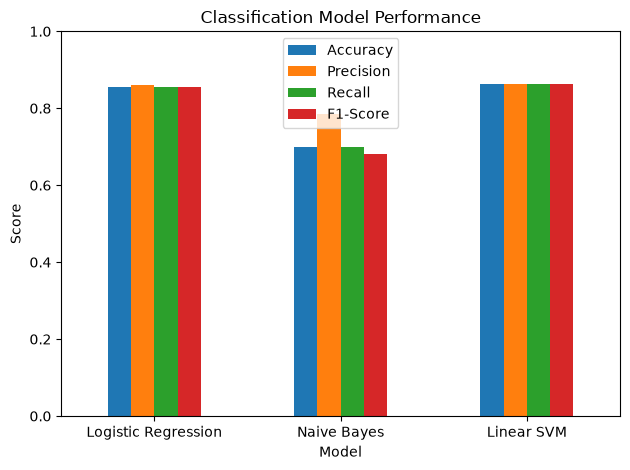

In [11]:
plt.figure(figsize=(9, 5))

evaluation_plot = evaluation_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

evaluation_plot.plot(kind="bar")

plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Detailed Evaluation of Best Model

In [12]:
from sklearn.metrics import classification_report

svm_report = classification_report(
    y_test,
    predictions["Linear SVM"],
    output_dict=True,
    zero_division=0
)

svm_report_df = pd.DataFrame(svm_report).transpose()

svm_report_df

,precision,recall,f1-score,support
Access,0.898388,0.899649,0.899018,1425.000000
Administrative rights,0.857627,0.718750,0.782071,352.000000
HR Support,0.865815,0.868988,0.867398,2183.000000
Hardware,0.830651,0.871512,0.850591,2724.000000
Internal Project,0.886700,0.849057,0.867470,424.000000
Miscellaneous,0.832743,0.832153,0.832448,1412.000000
Purchase,0.945652,0.882353,0.912907,493.000000
Storage,0.925000,0.866667,0.894884,555.000000
accuracy,0.862981,0.862981,0.862981,0.862981
macro avg,0.880322,0.848641,0.863348,9568.000000


## Confusion Matrix for Best Model

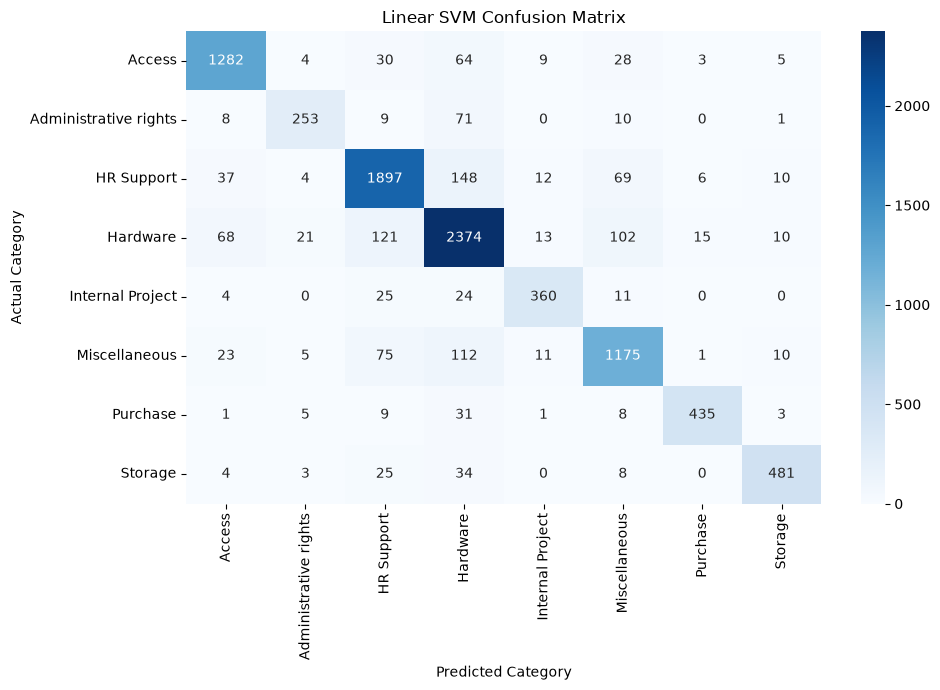

In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    predictions["Linear SVM"],
    labels=svm_report_df.index[:-3]
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_report_df.index[:-3],
    yticklabels=svm_report_df.index[:-3]
)

plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/category_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Saving Evaluation Results

In [14]:
evaluation_df.to_csv(
    "../outputs/category_model_evaluation.csv",
    index=False
)

svm_report_df.to_csv(
    "../outputs/category_classification_report.csv"
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


## Saving Professional Evaluation Results

In [15]:
# Professional model evaluation table

professional_evaluation = evaluation_df.copy()

professional_evaluation["Accuracy (%)"] = (
    professional_evaluation["Accuracy"] * 100
).round(2)

professional_evaluation["Precision (%)"] = (
    professional_evaluation["Precision"] * 100
).round(2)

professional_evaluation["Recall (%)"] = (
    professional_evaluation["Recall"] * 100
).round(2)

professional_evaluation["F1-Score (%)"] = (
    professional_evaluation["F1-Score"] * 100
).round(2)

professional_evaluation = professional_evaluation[
    ["Model", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]
]

professional_evaluation["Rank"] = (
    professional_evaluation["F1-Score (%)"]
    .rank(ascending=False, method="min")
    .astype(int)
)

professional_evaluation = professional_evaluation.sort_values("Rank")

professional_evaluation.to_csv(
    "../outputs/category_model_evaluation.csv",
    index=False
)


# Professional class-wise report

professional_report = svm_report_df.copy()

professional_report = professional_report.iloc[:-3].copy()

professional_report = professional_report.reset_index()
professional_report = professional_report.rename(
    columns={
        "index": "Category",
        "precision": "Precision (%)",
        "recall": "Recall (%)",
        "f1-score": "F1-Score (%)",
        "support": "Support"
    }
)

professional_report["Precision (%)"] = (
    professional_report["Precision (%)"] * 100
).round(2)

professional_report["Recall (%)"] = (
    professional_report["Recall (%)"] * 100
).round(2)

professional_report["F1-Score (%)"] = (
    professional_report["F1-Score (%)"] * 100
).round(2)

professional_report["Support"] = (
    professional_report["Support"].astype(int)
)

professional_report.to_csv(
    "../outputs/category_classification_report.csv",
    index=False
)

print("Professional evaluation files saved successfully.")

Professional evaluation files saved successfully.


## Saving Best Category Model

In [16]:
import joblib

joblib.dump(
    models["Linear SVM"],
    "../models/category_linear_svm.joblib"
)

joblib.dump(
    vectorizer,
    "../models/category_tfidf_vectorizer.joblib"
)

print("Best category model and TF-IDF vectorizer saved successfully.")

Best category model and TF-IDF vectorizer saved successfully.


## Creating Ticket Priority Labels

In [17]:
high_priority_words = [
    "urgent", "critical", "emergency", "outage",
    "security", "breach", "blocked", "down",
    "cannot access", "unable to access", "system failure"
]

medium_priority_words = [
    "error", "issue", "problem", "failure",
    "not working", "slow", "delayed", "access denied"
]

def assign_priority(text):
    text = text.lower()

    if any(word in text for word in high_priority_words):
        return "High"

    if any(word in text for word in medium_priority_words):
        return "Medium"

    return "Low"

df["Priority"] = df["Document"].apply(assign_priority)

print("Priority Distribution:")
print(df["Priority"].value_counts())

df[["Document", "Topic_group", "Priority"]].head(10)

Priority Distribution:
Priority
Low       32900
Medium    10549
High       4388
Name: count, dtype: int64


,Document,Topic_group,Priority
0,connection with icon icon dear please setup ic...,Hardware,Low
1,work experience user work experience user hi w...,Access,Low
2,requesting for meeting requesting meeting hi p...,Hardware,Low
3,reset passwords for external accounts re expir...,Access,Medium
4,mail verification warning hi has got attached ...,Miscellaneous,Low
5,mail please dear looks blacklisted receiving m...,Miscellaneous,Low
6,prod servers tunneling prod tunneling va la tu...,Hardware,Medium
7,access request dear modules report report cost...,HR Support,Low
8,reset passwords for our client and passwords c...,Access,Low
9,direct reports missing time please action repo...,HR Support,High


## Preparing Priority Classification

In [18]:
from sklearn.model_selection import train_test_split

X_priority = df["cleaned_text"]
y_priority = df["Priority"]

X_train_priority, X_test_priority, y_train_priority, y_test_priority = train_test_split(
    X_priority,
    y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

print("Training Samples:", len(X_train_priority))
print("Testing Samples:", len(X_test_priority))

print("\nPriority Distribution:")
print(y_priority.value_counts())

Training Samples: 38269
Testing Samples: 9568

Priority Distribution:
Priority
Low       32900
Medium    10549
High       4388
Name: count, dtype: int64


## Training Priority Classification Models

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

priority_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_priority_tfidf = priority_vectorizer.fit_transform(X_train_priority)
X_test_priority_tfidf = priority_vectorizer.transform(X_test_priority)

priority_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

priority_predictions = {}

for name, model in priority_models.items():
    model.fit(X_train_priority_tfidf, y_train_priority)
    priority_predictions[name] = model.predict(X_test_priority_tfidf)

print("All priority classification models trained successfully.")

All priority classification models trained successfully.


## Evaluating Priority Classification Models

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

priority_evaluation = []

for name, prediction in priority_predictions.items():
    priority_evaluation.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_priority, prediction),
        "Precision": precision_score(
            y_test_priority, prediction,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_priority, prediction,
            average="weighted",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_priority, prediction,
            average="weighted",
            zero_division=0
        )
    })

priority_evaluation_df = pd.DataFrame(priority_evaluation)

priority_evaluation_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.942099,0.943204,0.942099,0.938429
1,Naive Bayes,0.839256,0.848666,0.839256,0.816515
2,Linear SVM,0.971781,0.972057,0.971781,0.971025


## Comparing Priority Model Performance

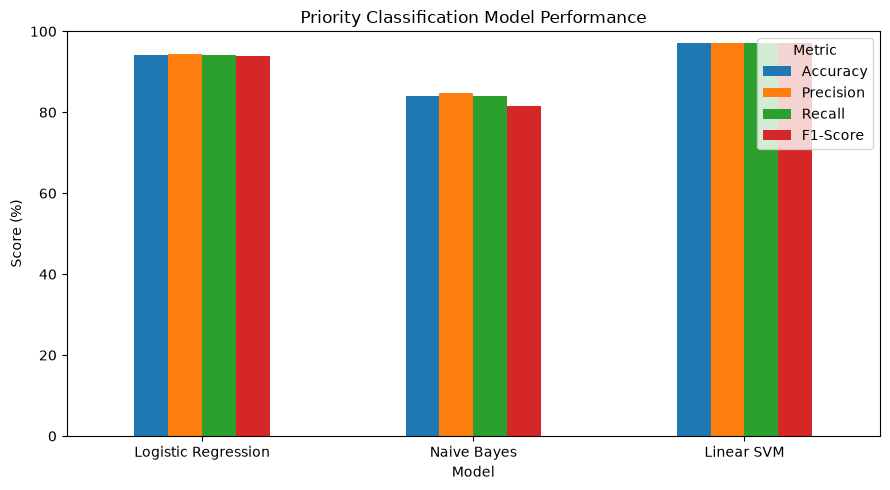

In [21]:
priority_plot = priority_evaluation_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    priority_plot[column] = priority_plot[column] * 100

priority_plot = priority_plot.set_index("Model")

ax = priority_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Priority Classification Model Performance")
ax.set_xlabel("Model")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/priority_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Detailed Evaluation of Best Priority Model

In [22]:
from sklearn.metrics import classification_report

priority_report = classification_report(
    y_test_priority,
    priority_predictions["Linear SVM"],
    output_dict=True,
    zero_division=0
)

priority_report_df = pd.DataFrame(priority_report).transpose()

priority_report_df

,precision,recall,f1-score,support
High,0.993075,0.816629,0.896250,878.000000
Low,0.974944,0.999392,0.987017,6580.000000
Medium,0.954307,0.950237,0.952268,2110.000000
accuracy,0.971781,0.971781,0.971781,0.971781
macro avg,0.974109,0.922086,0.945178,9568.000000
weighted avg,0.972057,0.971781,0.971025,9568.000000


In [23]:
## Priority Confusion Matrix## Priority Confusion Matrix

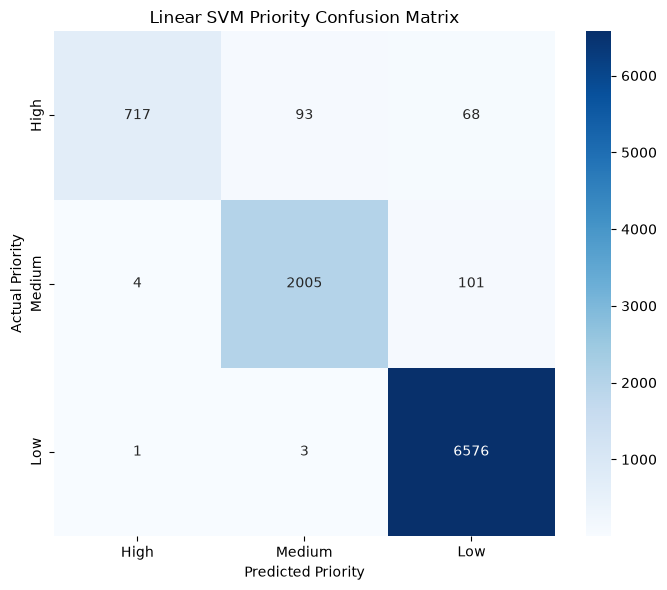

In [24]:
from sklearn.metrics import confusion_matrix

priority_cm = confusion_matrix(
    y_test_priority,
    priority_predictions["Linear SVM"],
    labels=["High", "Medium", "Low"]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    priority_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["High", "Medium", "Low"],
    yticklabels=["High", "Medium", "Low"]
)

plt.title("Linear SVM Priority Confusion Matrix")
plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/priority_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Saving Professional Priority Evaluation Results

In [25]:
priority_evaluation_professional = priority_evaluation_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    priority_evaluation_professional[column] = (
        priority_evaluation_professional[column] * 100
    ).round(2)

priority_evaluation_professional = priority_evaluation_professional.rename(
    columns={
        "Accuracy": "Accuracy (%)",
        "Precision": "Precision (%)",
        "Recall": "Recall (%)",
        "F1-Score": "F1-Score (%)"
    }
)

priority_evaluation_professional["Rank"] = (
    priority_evaluation_professional["F1-Score (%)"]
    .rank(ascending=False, method="min")
    .astype(int)
)

priority_evaluation_professional = (
    priority_evaluation_professional
    .sort_values("Rank")
)

priority_report_professional = priority_report_df.copy()

priority_report_professional = (
    priority_report_professional
    .iloc[:-3]
    .reset_index()
    .rename(columns={
        "index": "Priority",
        "precision": "Precision (%)",
        "recall": "Recall (%)",
        "f1-score": "F1-Score (%)",
        "support": "Support"
    })
)

for column in ["Precision (%)", "Recall (%)", "F1-Score (%)"]:
    priority_report_professional[column] = (
        priority_report_professional[column] * 100
    ).round(2)

priority_report_professional["Support"] = (
    priority_report_professional["Support"].astype(int)
)

priority_evaluation_professional.to_csv(
    "../outputs/priority_model_evaluation.csv",
    index=False
)

priority_report_professional.to_csv(
    "../outputs/priority_classification_report.csv",
    index=False
)

print("Professional priority evaluation files saved successfully.")

Professional priority evaluation files saved successfully.


## Saving Best Priority Model

In [26]:
import joblib

joblib.dump(
    priority_models["Linear SVM"],
    "../models/priority_linear_svm.joblib"
)

joblib.dump(
    priority_vectorizer,
    "../models/priority_tfidf_vectorizer.joblib"
)

print("Best priority model and TF-IDF vectorizer saved successfully.")

Best priority model and TF-IDF vectorizer saved successfully.


## Predict Category and Priority for a New Ticket

In [27]:
import re
import joblib

category_model = joblib.load("../models/category_linear_svm.joblib")
category_vectorizer = joblib.load("../models/category_tfidf_vectorizer.joblib")

priority_model = joblib.load("../models/priority_linear_svm.joblib")
priority_vectorizer = joblib.load("../models/priority_tfidf_vectorizer.joblib")


def clean_ticket(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def predict_ticket(ticket):
    cleaned_ticket = clean_ticket(ticket)

    category_features = category_vectorizer.transform([cleaned_ticket])
    priority_features = priority_vectorizer.transform([cleaned_ticket])

    category = category_model.predict(category_features)[0]
    priority = priority_model.predict(priority_features)[0]

    return category, priority


ticket = "My laptop is not working and I urgently need it for today's work."

category, priority = predict_ticket(ticket)

print("Ticket:", ticket)
print("Predicted Category:", category)
print("Predicted Priority:", priority)

Ticket: My laptop is not working and I urgently need it for today's work.
Predicted Category: Hardware
Predicted Priority: High


## Saving Sample Prediction

In [28]:
sample_prediction = pd.DataFrame([{
    "Ticket": ticket,
    "Predicted Category": category,
    "Predicted Priority": priority
}])

sample_prediction.to_csv(
    "../outputs/predictions/sample_predictions.csv",
    index=False
)

print("Sample prediction saved successfully.")
print(sample_prediction)

Sample prediction saved successfully.
                                              Ticket Predicted Category  \
0  My laptop is not working and I urgently need i...           Hardware   

  Predicted Priority  
0               High  


## Saving Processed Ticket Dataset

In [29]:
processed_df = df[
    ["Document", "cleaned_text", "Topic_group", "Priority"]
].copy()

processed_df.to_csv(
    "../data/processed/processed_tickets.csv",
    index=False
)

print("Processed dataset saved successfully.")
print("Shape:", processed_df.shape)

Processed dataset saved successfully.
Shape: (47837, 4)


## Final Model Performance Summary

In [30]:
final_summary = pd.DataFrame([
    {
        "Task": "Ticket Category Classification",
        "Best Model": "Linear SVM",
        "Accuracy (%)": 86.30,
        "Precision (%)": 86.39,
        "Recall (%)": 86.30,
        "F1-Score (%)": 86.30
    },
    {
        "Task": "Ticket Priority Classification",
        "Best Model": "Linear SVM",
        "Accuracy (%)": 97.18,
        "Precision (%)": 97.21,
        "Recall (%)": 97.18,
        "F1-Score (%)": 97.10
    }
])

final_summary.to_csv(
    "../outputs/final_model_summary.csv",
    index=False
)

final_summary

,Task,Best Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Ticket Category Classification,Linear SVM,86.30,86.39,86.30,86.3
1,Ticket Priority Classification,Linear SVM,97.18,97.21,97.18,97.1


## Final Project Results


In [31]:
final_results = pd.DataFrame([
    {
        "Task": "Category Classification",
        "Best Model": "Linear SVM",
        "Accuracy (%)": 86.30,
        "Precision (%)": 86.39,
        "Recall (%)": 86.30,
        "F1-Score (%)": 86.30,
        "Key Finding": "Linear SVM performed best among the three category classifiers."
    },
    {
        "Task": "Priority Classification",
        "Best Model": "Linear SVM",
        "Accuracy (%)": 97.18,
        "Precision (%)": 97.21,
        "Recall (%)": 97.18,
        "F1-Score (%)": 97.10,
        "Key Finding": "Linear SVM performed best for the derived priority labels."
    }
])

final_results.to_csv(
    "../outputs/final_results_report.csv",
    index=False
)

print("Final results report saved successfully.")
print(final_results)

Final results report saved successfully.
                      Task  Best Model  Accuracy (%)  Precision (%)  \
0  Category Classification  Linear SVM         86.30          86.39   
1  Priority Classification  Linear SVM         97.18          97.21   

   Recall (%)  F1-Score (%)                                        Key Finding  
0       86.30          86.3  Linear SVM performed best among the three cate...  
1       97.18          97.1  Linear SVM performed best for the derived prio...  


In [33]:
## Final Prediction Demo

In [34]:
sample_tickets = [
    "My laptop screen is not working.",
    "I cannot access the company storage drive.",
    "There is an urgent security issue with my account.",
    "I need to purchase a new software license."
]

prediction_results = []

for ticket_text in sample_tickets:
    category, priority = predict_ticket(ticket_text)

    prediction_results.append({
        "Ticket": ticket_text,
        "Predicted Category": category,
        "Predicted Priority": priority
    })

prediction_results_df = pd.DataFrame(prediction_results)

prediction_results_df.to_csv(
    "../outputs/predictions/final_prediction_demo.csv",
    index=False
)

prediction_results_df

,Ticket,Predicted Category,Predicted Priority
0,My laptop screen is not working.,Hardware,Medium
1,I cannot access the company storage drive.,Storage,High
2,There is an urgent security issue with my acco...,Access,High
3,I need to purchase a new software license.,Access,Low


## Project Insights

In [35]:
insights = [
    "Linear SVM achieved the best performance for ticket category classification.",
    "Category classification achieved 86.30% accuracy and 86.30% F1-score.",
    "Linear SVM achieved the best performance for priority classification.",
    "Priority classification achieved 97.18% accuracy and 97.10% F1-score.",
    "Administrative rights was the most challenging category based on recall.",
    "High priority had lower recall than Medium and Low priority.",
    "TF-IDF with unigram and bigram features provided effective text representation.",
    "The priority labels were derived using predefined business rules because the original dataset does not contain priority labels."
]

insights_df = pd.DataFrame({
    "No.": range(1, len(insights) + 1),
    "Project Insight": insights
})

insights_df.to_csv(
    "../outputs/project_insights.csv",
    index=False
)

print("Project insights saved successfully.")
print(insights_df)

Project insights saved successfully.
   No.                                    Project Insight
0    1  Linear SVM achieved the best performance for t...
1    2  Category classification achieved 86.30% accura...
2    3  Linear SVM achieved the best performance for p...
3    4  Priority classification achieved 97.18% accura...
4    5  Administrative rights was the most challenging...
5    6  High priority had lower recall than Medium and...
6    7  TF-IDF with unigram and bigram features provid...
7    8  The priority labels were derived using predefi...
